
<div dir=ltr align=center>

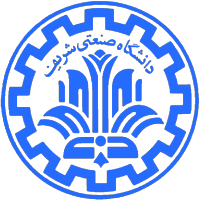

<font color=0F5298 size=7>
Machine Learning <br>
<font color=2565AE size=5>
Computer Engineering Department <br>
Fall 2025 <br>
<font color=3C99D size=5>
    Clustering: Gaussian Mixture Model <br>
<font color=696880 size=4>
    Prepared by Benyamin Ghanbari <br>

<font color=696880 size=2>
    Curated by Alireza Mirshafieian

____

# Student Information

In [ ]:
student_number = '402106701'
full_name = 'Arshia Nazari'

# Customer Segmentation Using GMM 

## Description:
In this project, you will implement a Gaussian Mixture Model (GMM) from scratch and use it to perform customer segmentation based on demographic and behavioral data. Customer segmentation is the process of grouping customers into clusters such that customers within the same cluster are more similar to each other than to those in other clusters. In this assignment, segmentation is done using a probabilistic clustering approach, where each customer is assigned a probability of belonging to each cluster based on features such as Age, Annual Income, and Spending Score. 

**⚠️ Notice:** You are allowed to use only the imported libraries and must follow the provided function structure.

# 📝 **Project Instructions**

1. **Load the customer dataset**  
   Load the dataset containing customer information such as **Age, Annual Income, Spending Score**, and optionally **Gender**.

2. **Feature selection**  
    Anything that you need.

3. **Standardize features**  
   Normalize the numerical features using **standardization** so that each feature has **mean 0 and standard deviation 1**.

4. **Initialize GMM parameters**  
   Randomly initialize **cluster weights, means, and covariance matrices** for a chosen number of clusters **K**.

5. **Expectation-Maximization (EM) steps**  
   - **Expectation step:** Compute the **responsibility** of each cluster for every customer.  
   - **Maximization step:** Update **weights, means, and covariances** based on responsibilities.  
   - Repeat until **log-likelihood converges** or **max iterations** is reached.

6. **Multiple initializations**  
   Run the GMM algorithm **multiple times** with different random seeds and select the model with the **highest log-likelihood** to avoid poor local minima.

7. **Select the optimal number of clusters**  
   Compute **BIC (Bayesian Information Criterion)** for different values of **K** and choose the one with the **lowest BIC**.

8. **Assign clusters to customers**  
   For the final model, assign each customer to the cluster with the **highest responsibility**.

9. **Visualize clusters**  
   - **2D scatter plots:** Plot feature pairs (e.g., Age vs Income, Age vs Spending Score) with points colored by cluster.  
   - **Cluster centroids and circles:** Highlight **cluster centers** and **spread** using semi-transparent colored circles.  
   - **3D scatter plot:** Visualize clusters in 3D with **centroids marked**.



# 📤 **Expected Output**

- A **clustered customer dataset** showing each customer assigned to a **GMM cluster**  
- **2D scatter plots** of feature pairs (e.g., Age vs Income, Age vs Spending Score, Income vs Spending Score) with:  
  - Cluster points colored by cluster  
  - **Centroids** marked  
  - **Semi-transparent circles** showing cluster spread  
- A **3D scatter plot** visualizing all three features with cluster centroids highlighted  
- A **BIC vs. K plot** showing the Bayesian Information Criterion for different numbers of clusters, helping identify the **optimal K**  
- **Observe** which features distinguish clusters and how changing **K** affects segmentation quality


In [157]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Circle

In [158]:
# read data 

df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [159]:
# data prepration (feature selection and scaling)

X = df[['Age','Annual Income (k$)', 'Spending Score (1-100)']].values # selected feature 

def standard_scale(X):
    means = np.mean(X, axis=0)
    stds = np.std(X, axis=0)
    stds[stds == 0] = 1.0
    X_scaled = (X - means) / stds
    return X_scaled, means, stds

X_scaled, means_X, stds_X = standard_scale(X)


In [160]:
# GMM from scratch

def gaussian_pdf_all(X, mean, cov):
    n = X.shape[1]
    cov_det = np.linalg.det(cov)
    if cov_det <= 0:
        cov_det = 1e-6
    cov_inv = np.linalg.inv(cov + 1e-6 * np.eye(n))
    norm_const = 1.0 / ((2 * np.pi) ** (n / 2) * np.sqrt(cov_det))
    X_mean = X - mean
    exponent = -0.5 * np.sum(X_mean @ cov_inv * X_mean, axis=1)

    norm_const = np.log(norm_const) #because of return exp
    return np.exp(norm_const + exponent)

def initialize_parameters(X, k, rng):
    n_samples, n_features = X.shape
    weights = np.ones(k) / k
    indices = rng.choice(n_samples, k, replace=False)
    means = X[indices]
    covs = np.array([np.eye(n_features) for _ in range(k)])
    return weights, means, covs

def expectation_step(X, weights, means, covs):
    n_samples = X.shape[0]
    k = len(weights)
    resp = np.zeros((n_samples, k))
    for i in range(k):
        resp[:, i] = weights[i] * gaussian_pdf_all(X, means[i], covs[i])
    total_prob = np.sum(resp, axis=1, keepdims=True)
    resp = resp / (total_prob + 1e-10) # != 0
    return resp

def maximization_step(X, resp):
    n_samples, n_features = X.shape
    k = resp.shape[1]
    
    Nk = np.sum(resp, axis=0)
    weights = Nk / n_samples
    
    means = np.zeros((k, n_features))
    covs = np.zeros((k, n_features, n_features))
    
    for i in range(k):
        means[i] = np.sum(resp[:, i].reshape(-1, 1) * X, axis=0) / (Nk[i] + 1e-10)
        diff = X - means[i]
        weighted_diff = resp[:, i].reshape(-1, 1) * diff
        covs[i] = np.dot(weighted_diff.T, diff) / (Nk[i] + 1e-10)
        
    return weights, means, covs

def compute_log_likelihood(X, weights, means, covs):
    n_samples = X.shape[0]
    k = len(weights)
    
    prob_sum = np.zeros(n_samples)
    for i in range(k):
        prob_sum += weights[i] * gaussian_pdf_all(X, means[i], covs[i])
    
    ll = np.sum(np.log(prob_sum + 1e-10))
    return ll

def gmm_train(X, k, max_iter=200, tol=1e-4, seed=None):
    rng = np.random.default_rng(seed)
    weights, means, covs = initialize_parameters(X, k, rng)
    log_likelihoods = []
    
    for i in range(max_iter):
        resp = expectation_step(X, weights, means, covs)
        new_weights, new_means, new_covs = maximization_step(X, resp)
        
        ll = compute_log_likelihood(X, weights, means, covs)
        log_likelihoods.append(ll)
        
        if i > 0 and abs(ll - log_likelihoods[-2]) < tol:
            break
            
        weights, means, covs = new_weights, new_means, new_covs
            
    return weights, means, covs, resp, ll

In [161]:
# compute best k using BIC

def compute_bic(ll, k, n, d):
    num_params = k * d + k * d * (d + 1) / 2 + (k - 1)
    return -2*ll + num_params * np.log(n)

bic_values = []
k_range = range(2,9)
best_models = {}

# to do 
#.......
for k in k_range:
    best_ll_k = -np.inf
    best_model = None
    for seed in range(100): #by changing it we have different k's(k==4 , k==5), like with 3 we have k==4 and with 5 or above we have k == 5
                            #change it to range(3) to see clustering polts like the expected resualt, althou.. clusters have different idx.
        weights, means, covs, resp, ll = gmm_train(X_scaled, k, seed=seed * 10 + k)
        if ll > best_ll_k:
            best_ll_k = ll
            best_model = (weights, means, covs, resp)
    bic = compute_bic(best_ll_k, k, X_scaled.shape[0], X_scaled.shape[1])
    bic_values.append(bic)
    best_models[k] = best_model
    
best_k_idx = np.argmin(bic_values)
best_k = k_range[best_k_idx]

print("\nBest k =", best_k)



Best k = 5


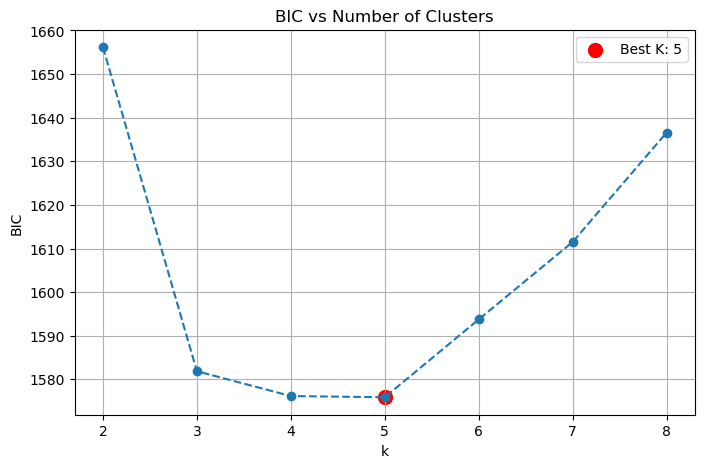

In [162]:
# BIC plot 
plt.figure(figsize=(8, 5))
plt.plot(k_range, bic_values, marker='o', linestyle='--')
plt.scatter(best_k, bic_values[best_k_idx], color='red', s=100, label=f'Best K: {best_k}')
plt.title('BIC vs Number of Clusters')
plt.xlabel('k')
plt.ylabel('BIC')
plt.legend()
plt.grid(True)
plt.show()

In [163]:
# train final model
final_weights, final_means, final_covs, final_resp = best_bic_models[best_k]
df['Cluster'] = np.argmax(final_resp, axis=1)
print(df['Cluster'])
#to see how many elements we have in each cluster
print(df['Cluster'].value_counts().sort_index())

0      3
1      4
2      3
3      4
4      3
      ..
195    2
196    1
197    2
198    1
199    2
Name: Cluster, Length: 200, dtype: int64
Cluster
0    82
1    32
2    39
3    26
4    21
Name: count, dtype: int64


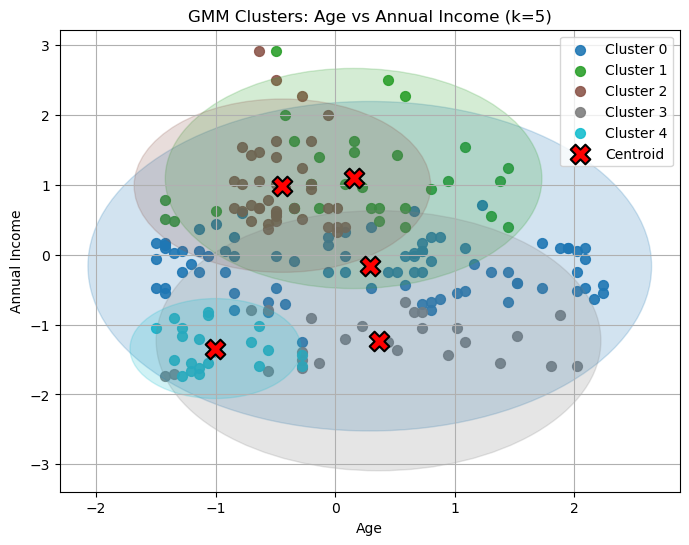

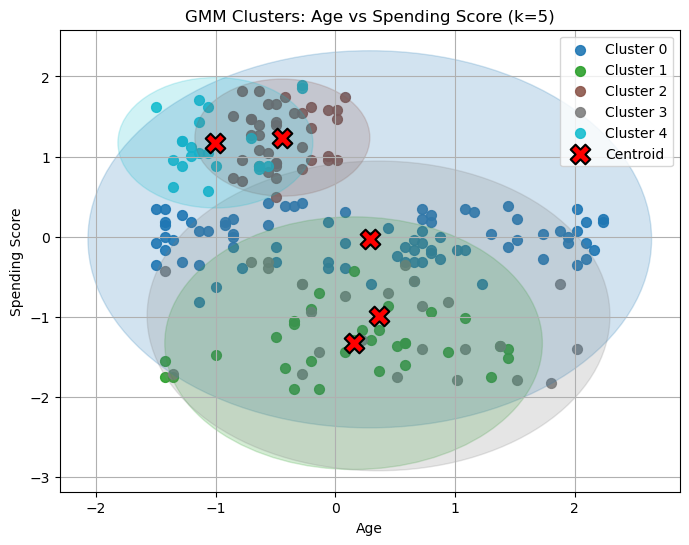

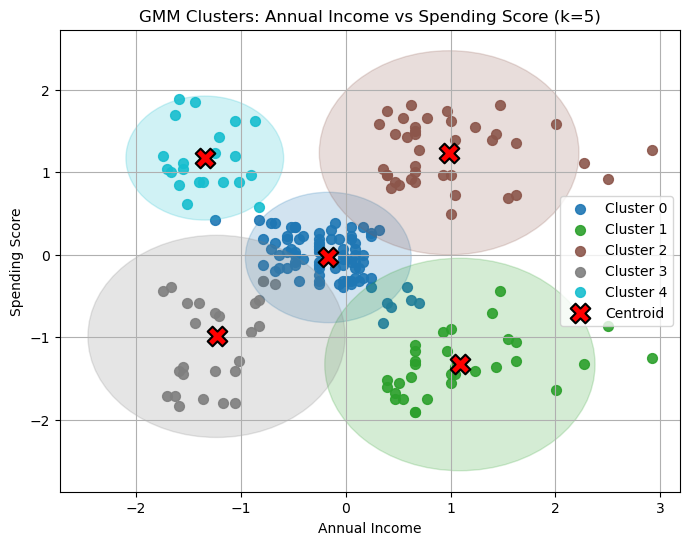

In [164]:
# 2D plot with cluster circles and centroid
def plot_2d(data, labels, means, covs, idx1, idx2, names, k):
    plt.figure(figsize=(8,6))
    colors = plt.cm.tab10(np.linspace(0, 1, k)) # to be scale automaticly with k
    for i in range(k):
        plt.scatter(data[labels == i, idx1], data[labels == i, idx2],s=50, color=colors[i], alpha=0.9, label=f'Cluster {i}')
    plt.scatter(means[:, idx1], means[:, idx2], s=200, marker='X',c='red', edgecolors='black', linewidth=1.5, zorder=10,label = 'Centroid')
    ax = plt.gca()
    for i in range(k):
        cov_2d = covs[i][np.ix_([idx1, idx2], [idx1, idx2])]

        eigvals = np.linalg.eigvalsh(cov_2d)
        radius = 2.0 * np.sqrt(np.max(eigvals))

        circ = Circle((means[i, idx1], means[i, idx2]), radius, 
                      color=colors[i], alpha=0.2)
        ax.add_patch(circ)
    plt.title(f'GMM Clusters: {names[idx1]} vs {names[idx2]} (k={k})')
    plt.xlabel(names[idx1])
    plt.ylabel(names[idx2])
    plt.legend()
    plt.grid(True)
    plt.show()
        
feature_names = ['Age', 'Annual Income', 'Spending Score']
plot_2d(X_scaled, df['Cluster'], final_means, final_covs, 0, 1, feature_names, best_k)
plot_2d(X_scaled, df['Cluster'], final_means, final_covs, 0, 2, feature_names, best_k)
plot_2d(X_scaled, df['Cluster'], final_means, final_covs, 1, 2, feature_names, best_k)

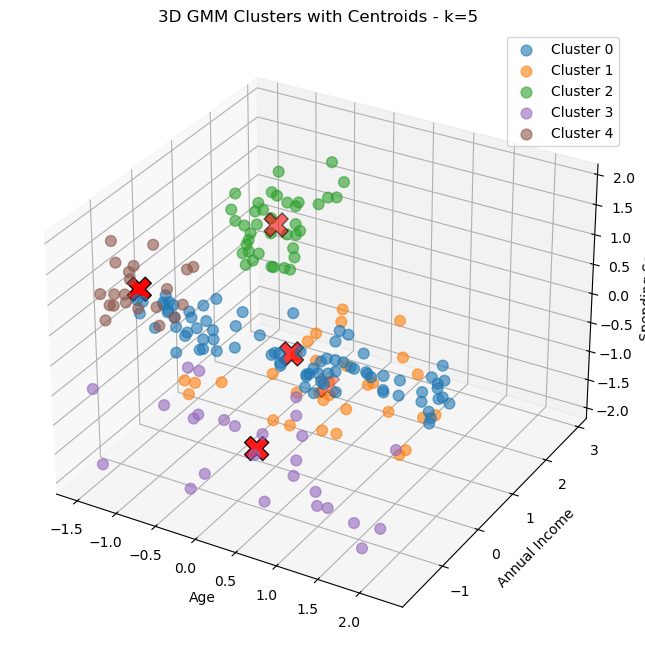

In [165]:
# 3D plot with cluster centroids
colors = plt.cm.tab10(np.linspace(0, 1, k))
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for i in range(best_k):
    cluster_points = X_scaled[df['Cluster'] == i]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2],s=60, color=colors[i], alpha=0.6, label=f'Cluster {i}')
ax.scatter(final_means[:, 0], final_means[:, 1], final_means[:, 2], s=300, marker='X', c='red', edgecolors='black', zorder=10)
ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
ax.set_zlabel(feature_names[2])
ax.set_title(f'3D GMM Clusters with Centroids - k={best_k}')
ax.legend()
plt.show()

In [166]:
# save segmented result 
df.to_csv('GMM_customer_segmentation.csv', index=False)
print("\nFirst 10 rows of segmented data:")
print(df.head(10))



First 10 rows of segmented data:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        3  
1        4  
2        3  
3        4  
4        3  
5        4  
6        3  
7        4  
8        3  
9        4  


In [ ]:
# Your first 10 row shoud be like : 
#with k=4 or k=5 base on random function and iter number we find that the clustering is right and they put in this order to clusters
#and with both k we have : clusterx clustery clusterx clustery ... for first 10, you can also check it on plots to see its true, and in the 
#'compute best k using BIC i explain to how to have k == 5 and k==4

,Unnamed: 0,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,0,1,Male,19,15,39,3
1,1,2,Male,21,15,81,0
2,2,3,Female,20,16,6,3
3,3,4,Female,23,16,77,0
4,4,5,Female,31,17,40,3
5,5,6,Female,22,17,76,0
6,6,7,Female,35,18,6,3
7,7,8,Female,23,18,94,0
8,8,9,Male,64,19,3,3
9,9,10,Female,30,19,72,0
